# Single-Trace Attack on Falcon-1024 - Live Demo

From **one** power trace of the device signing, recover the **entire** secret key.

- **Leakage, templates, accuracy:** measured on an STM32F4 (Cortex-M4, 1 GS/s).
- The secret-key decode (`trim_i8_decode`) is byte-identical for Falcon-512 and
  Falcon-1024, so the measured accuracy projects directly; Falcon-1024 just packs
  coefficients in **[-15, 15]** (5 bits).
- **Full-key recovery** runs on a genuine Falcon-1024 key `(f, g, h)`, `h = g/f mod x^1024+1`.

Run top to bottom.


In [1]:
import os, sys, time, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(os.path.join('..', 'template_attack')))
import falcon_keymath as km

Cf = np.load('nb_corr_full.npz'); corr = Cf['corr']; trace = Cf['example'].astype(float)
L = np.load('demo_leak_model.npz'); true_c, pred_c, marg_c = L['true'], L['pred'], L['margin']
pool = {}
for t, p, m in zip(true_c, pred_c, marg_c): pool.setdefault(int(t), []).append((int(p), float(m)))
K = np.load('nb_falcon1024.npz'); f_true = K['f'].astype(int); g_true = K['g'].astype(int)
h = K['h'].astype(np.uint32); N = km.N
single_acc = 100 * float(np.mean(true_c == pred_c))
print(f'Loaded: 1 target trace, combined 2-point template, Falcon-{N} key (n={N}).')
print(f'Measured single-trace per-coefficient accuracy: {single_acc:.2f}%')


Loaded: 1 target trace, combined 2-point template, Falcon-1024 key (n=1024).
Measured single-trace per-coefficient accuracy: 98.32%


## 1. The target trace: one Falcon-1024 signing

This is a single power trace of the device signing. The secret key passes through the
device in the clear at **two** places, both highlighted below:

- **Attack Point 1 - decode** (orange, near the start): the key is unpacked coefficient by
  coefficient.
- **Attack Point 2 - mod-q** (red, later): each coefficient is converted for the mod-q
  arithmetic.

Both carry the secret, and we use both.


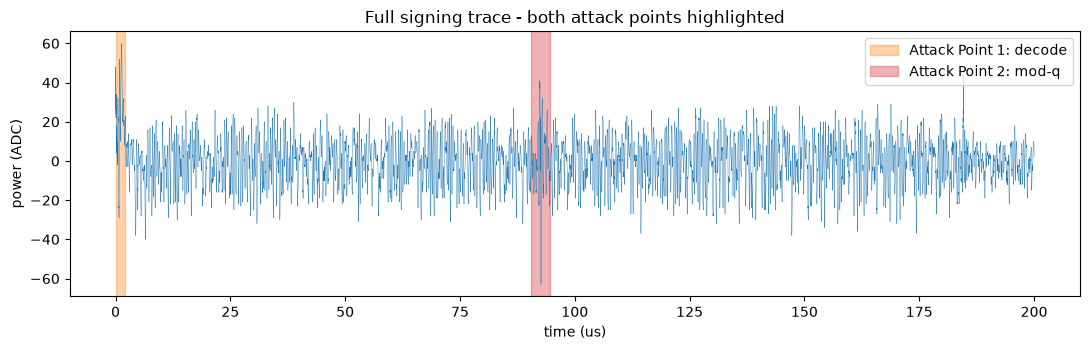

In [2]:
t_us = np.arange(len(trace)) / 1000.0
plt.figure(figsize=(11, 3.6))
plt.plot(t_us, trace, lw=.3, color='C0')
plt.axvspan(0, 2.0, color='C1', alpha=.35, label='Attack Point 1: decode')
plt.axvspan(90.5, 94.5, color='C3', alpha=.35, label='Attack Point 2: mod-q')
plt.title('Full signing trace - both attack points highlighted')
plt.xlabel('time (us)'); plt.ylabel('power (ADC)'); plt.legend(loc='upper right')
plt.tight_layout(); plt.show()


## 2. Two attack points in the decode

Correlating the power with the secret coefficient across one signing shows **two** leak
points, and we use **both**:

- **Attack Point 1 - decode** (sign-extension, `w |= -(w & mask2)`): very strong, `|rho| ~ 0.97`.
- **Attack Point 2 - mod-q** (two's-complement negation, `x = -f[i]`): weak on its own,
  `|rho| ~ 0.38`, but it leaks a *different* function of the same coefficient.

Point 2's low correlation is still useful: it carries exactly the information Point 1 is
missing (next cell).


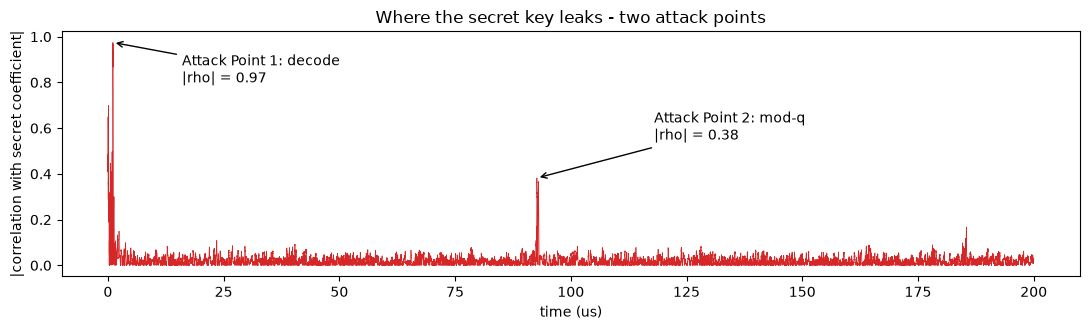

In [3]:
t_us = np.arange(len(corr)) / 1000.0
plt.figure(figsize=(11, 3.4))
plt.plot(t_us, corr, lw=.5, color='C3')
plt.annotate('Attack Point 1: decode\n|rho| = 0.97', xy=(1.1, corr[1093]),
             xytext=(16, 0.80), arrowprops=dict(arrowstyle='->'), fontsize=10)
plt.annotate('Attack Point 2: mod-q\n|rho| = 0.38', xy=(92.7, corr[92676]),
             xytext=(118, 0.55), arrowprops=dict(arrowstyle='->'), fontsize=10)
plt.xlabel('time (us)'); plt.ylabel('|correlation with secret coefficient|')
plt.title('Where the secret key leaks - two attack points'); plt.tight_layout(); plt.show()


## 3. Why we need both points: the Hamming-weight collision

Power leakage on this chip tracks the **Hamming weight** (number of 1-bits) of the 32-bit
value. At **Point 1** the value is the coefficient itself; at **Point 2** it is the
**negated** coefficient - a different bit pattern.

`+5` and `+6` have the **same** Hamming weight at Point 1 (both 2) - they *collide*, Point 1
cannot tell them apart. But their negatives have **different** Hamming weights at Point 2
(31 vs 30). So Point 2 separates exactly the values that Point 1 confuses.


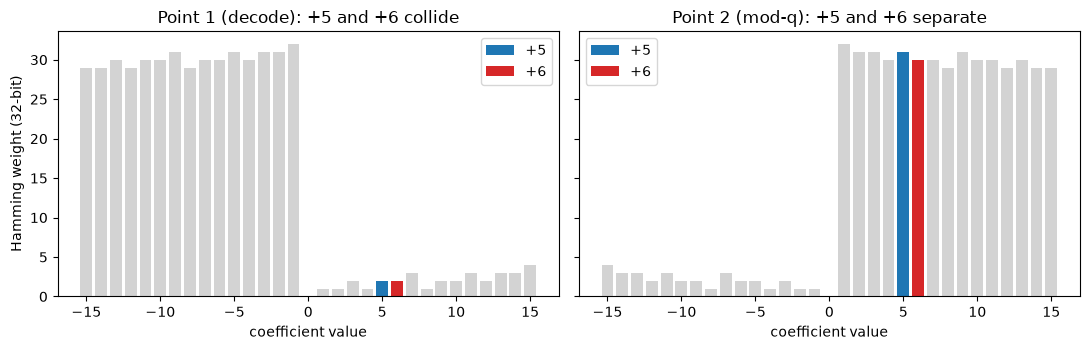

Point 1 Hamming weight:  +5 -> 2  +6 -> 2  (collision)
Point 2 Hamming weight:  +5 -> 31  +6 -> 30  (separated)


In [4]:
vals = np.arange(-15, 16)
hw1 = np.array([bin(int(v) & 0xFFFFFFFF).count('1') for v in vals])   # decode value
hw2 = np.array([bin((-int(v)) & 0xFFFFFFFF).count('1') for v in vals]) # negated value
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, hw, ttl in ((ax[0], hw1, 'Point 1 (decode): +5 and +6 collide'),
                   (ax[1], hw2, 'Point 2 (mod-q): +5 and +6 separate')):
    a.bar(vals, hw, color='lightgray')
    for v, c in ((5, 'C0'), (6, 'C3')):
        a.bar(v, hw[vals == v][0], color=c, label=f'+{v}')
    a.set_title(ttl); a.set_xlabel('coefficient value'); a.legend()
ax[0].set_ylabel('Hamming weight (32-bit)')
plt.tight_layout(); plt.show()
print('Point 1 Hamming weight:  +5 ->', hw1[vals == 5][0], ' +6 ->', hw1[vals == 6][0], ' (collision)')
print('Point 2 Hamming weight:  +5 ->', hw2[vals == 5][0], ' +6 ->', hw2[vals == 6][0], ' (separated)')


## 4. Reading the secret key from ONE trace

We now apply the combined two-point template to the target trace. Each coefficient gets a
**recovered value** and a **confidence**. Below are the recovered secret coefficients
`f[0] ... f[15]` - this is the actual key being read out of a single trace.

*(Single trace, N = 1. The measured per-coefficient accuracy is 98.32%.)*


In [5]:
rng = np.random.default_rng(1)
reads_f = [pool[int(v)][rng.integers(len(pool[int(v)]))] for v in f_true]  # (value, confidence)
reads_g = [pool[int(v)][rng.integers(len(pool[int(v)]))] for v in g_true]

rec_f = np.array([r[0] for r in reads_f])
print('recovered f[0:16] :', rec_f[:16].tolist())
print('true      f[0:16] :', f_true[:16].tolist())
print()
print(f"{'coeff':>6} | {'true':>5} | {'recovered':>9} | {'confidence':>10} | ok")
print('-' * 50)
for i in range(16):
    pr, mg = reads_f[i]
    print(f'  f[{i:>2d}] | {f_true[i]:>+5d} | {pr:>+9d} | {mg:>10.2f} | ' + ('ok' if pr == f_true[i] else 'X'))

n_ok = int((rec_f == f_true).sum()) + int((np.array([r[0] for r in reads_g]) == g_true).sum())
print(f'\nsingle trace: {n_ok}/{2*N} coefficients correct  ({100*n_ok/(2*N):.2f}%)')


recovered f[0:16] : [2, 0, 1, -2, 3, 5, -1, -3, 0, 5, 0, 4, -2, 0, 3, 1]
true      f[0:16] : [2, 0, 1, -2, 3, 5, -1, -3, 0, 5, 0, 4, -2, 0, 3, 1]

 coeff |  true | recovered | confidence | ok
--------------------------------------------------
  f[ 0] |    +2 |        +2 |       0.21 | ok
  f[ 1] |    +0 |        +0 |       3.43 | ok
  f[ 2] |    +1 |        +1 |       0.55 | ok
  f[ 3] |    -2 |        -2 |       0.73 | ok
  f[ 4] |    +3 |        +3 |       1.59 | ok
  f[ 5] |    +5 |        +5 |       0.24 | ok
  f[ 6] |    -1 |        -1 |       4.01 | ok
  f[ 7] |    -3 |        -3 |       0.16 | ok
  f[ 8] |    +0 |        +0 |       3.96 | ok
  f[ 9] |    +5 |        +5 |       0.01 | ok
  f[10] |    +0 |        +0 |       3.26 | ok
  f[11] |    +4 |        +4 |       2.48 | ok
  f[12] |    -2 |        -2 |       0.09 | ok
  f[13] |    +0 |        +0 |       3.48 | ok
  f[14] |    +3 |        +3 |       1.95 | ok
  f[15] |    +1 |        +1 |       0.56 | ok

single trace: 2020/2

## 5. 98% per coefficient is not yet the key

A Falcon-1024 key has **2048** secret coefficients (1024 in `f`, 1024 in `g`), and **every
one** must be correct. At 98.32% each, the chance all 2048 are right is essentially zero -
about **34 wrong coefficients per key**, and we do not know which. So the side channel alone
does not give the key.


In [6]:
p = single_acc / 100
print(f'per-coefficient accuracy : {100*p:.2f}%')
print(f'P(all 2048 correct)      : {p**(2*N):.2e}   (basically never)')
print(f'expected wrong per key   : {2*N*(1-p):.1f} coefficients')


per-coefficient accuracy : 98.32%
P(all 2048 correct)      : 8.78e-16   (basically never)
expected wrong per key   : 34.4 coefficients


## 6. The public key finishes the job

The public key gives a free linear relation: `H * f = g (mod 12289)`, where `H` is the
negacyclic matrix of the **public** `h`. That is `n = 1024` equations in the `2n = 2048`
unknowns, so knowing any **1024** coefficients pins the rest.

We **rank all 2048 coefficients by confidence**, keep the **top 1030** (just above 1024;
the low-confidence collisions drop out and the kept ones are error-free), solve for the
rest, and **verify** `H*f == g` using only public information - no lattice reduction.


In [7]:
cand = []
for i in range(N):
    cand.append((reads_f[i][1], 'f', i, reads_f[i][0]))
    cand.append((reads_g[i][1], 'g', i, reads_g[i][0]))
cand.sort(reverse=True)
top = cand[:1030]
kf = {i: v for _, t, i, v in top if t == 'f'}
kg = {i: v for _, t, i, v in top if t == 'g'}
print(f'kept top 1030 of 2048 by confidence -> {len(kf)} of f + {len(kg)} of g known, {2*N-len(kf)-len(kg)} unknown')

t0 = time.time()
ff, gg = km.solve_completion_fast(h, kf, kg)
dt = time.time() - t0
fr = np.array([km.to_signed(v) for v in ff]); gr = np.array([km.to_signed(v) for v in gg])

Hf = (km.negacyclic_matrix(h) @ (fr % km.Q)) % km.Q   # public-key check: H*f == g
verified = np.array_equal(Hf, gr % km.Q)
recovered = np.array_equal(fr, f_true) and np.array_equal(gr, g_true)

print(f'\nsolved in {dt:.1f}s (pure Python; ~0.5s in optimized C)')
print('recovered f[0:16] :', fr[:16].tolist())
print('true      f[0:16] :', f_true[:16].tolist())
print('recovered g[0:16] :', gr[:16].tolist())
print('true      g[0:16] :', g_true[:16].tolist())
print('\nH*f == g  (public-key check) :', 'PASS' if verified else 'FAIL')
print('FULL SECRET KEY RECOVERED    :', 'YES' if recovered else 'NO')


kept top 1030 of 2048 by confidence -> 490 of f + 540 of g known, 1018 unknown



solved in 10.5s (pure Python; ~0.5s in optimized C)
recovered f[0:16] : [2, 0, 1, -2, 3, 5, -1, -3, 0, 5, 0, 4, -2, 0, 3, 1]
true      f[0:16] : [2, 0, 1, -2, 3, 5, -1, -3, 0, 5, 0, 4, -2, 0, 3, 1]
recovered g[0:16] : [-7, 4, 2, -2, -2, 4, -3, 3, 4, 2, 0, 2, 0, 3, -2, 5]
true      g[0:16] : [-7, 4, 2, -2, -2, 4, -3, 3, 4, 2, 0, 2, 0, 3, -2, 5]

H*f == g  (public-key check) : PASS
FULL SECRET KEY RECOVERED    : YES


## Summary

| step | result |
|---|---|
| attack points | decode (`|rho|~0.97`) + mod-q (`|rho|~0.38`) |
| per-coefficient accuracy (single trace) | 98.32% |
| wrong coefficients per key | ~34 of 2048 |
| public-key completion | full key recovered & verified |
| recovery | one GF(q) solve, no lattice reduction |

**One trace + the public key breaks Falcon-1024.** The decode leaks the whole key in the
clear; two attack points resolve the Hamming-weight collisions; and the public relation
`H*f = g` turns an imperfect read into the exact secret key.
